# Phase 5: Model Training, Validation, and Evaluation

## Objective

Develop and compare forecasting models for industrial energy consumption at:
- 15 minutes ahead (`target_15min`)
- 1 hour ahead (`target_1hour`)

## Models

1. Linear Regression
2. Random Forest
3. XGBoost
4. LightGBM
5. K-Nearest Neighbours (KNN)
6. Support Vector Regression (SVR)

## Feature sets

- X_A: historical energy-use lags and calendar features
- X_B: X_A plus lagged electrical sensor readings
- X_C: X_B plus current electrical sensor readings

## Methodology

- Chronological training, validation, and test periods
- Four-row purge at the training/test boundary
- Time-series cross-validation for model comparison
- Persistence baseline
- MAE, RMSE, and R² evaluation
- Residual analysis and final model comparison

The final test period must not be used for feature selection or hyperparameter tuning.

## imports and paths

In [ ]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path("../Data/processed")
DATA_PATH = DATA_DIR / "steel_industry_model_ready.csv"
CONFIG_PATH = DATA_DIR / "feature_config.json"

RANDOM_STATE = 42

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

if not CONFIG_PATH.exists():
    raise FileNotFoundError(f"Feature config not found: {CONFIG_PATH.resolve()}")

print("Imports complete.")
print("Dataset:", DATA_PATH.resolve())

Imports complete.
Dataset: D:\Research Paper Codes\Data\processed\steel_industry_model_ready.csv


## load and validate data

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    feature_config = json.load(f)

features_A = feature_config["X_A"]
features_B = feature_config["X_B"]
features_C = feature_config["X_C"]

targets = ["target_15min", "target_1hour"]

df = (
    df.sort_values("timestamp")
      .reset_index(drop=True)
)

assert df["timestamp"].notna().all()
assert df["timestamp"].is_unique
assert df["timestamp"].is_monotonic_increasing

expected_interval = pd.Timedelta(minutes=15)
intervals = df["timestamp"].diff().dropna()

assert (intervals == expected_interval).all(), (
    "Dataset must contain regular 15-minute observations."
)

for target in targets:
    assert target in df.columns, f"Missing target: {target}"

for feature_set in [features_A, features_B, features_C]:
    missing = [col for col in feature_set if col not in df.columns]
    assert not missing, f"Missing predictor columns: {missing}"

assert not set(targets).intersection(features_A)
assert not set(targets).intersection(features_B)
assert not set(targets).intersection(features_C)

print("Dataset shape:", df.shape)
print("Time range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("Feature counts:", len(features_A), len(features_B), len(features_C))
print("Target columns:", targets)

Dataset shape: (34940, 28)
Time range: 2018-01-02 00:00:00 to 2018-12-31 22:45:00
Feature counts: 8 12 16
Target columns: ['target_15min', 'target_1hour']


## Forecast-Origin and Leakage Policy

At forecast origin t, the model predicts energy consumption at t+1 or t+4.

- `usage_lag_0` means energy consumption observed at time t.
- `usage_lag_1`, `usage_lag_2`, `usage_lag_4`, and `usage_lag_96` represent historical readings.
- Lagged sensor features use previous observations.
- X_C includes current sensor readings and is only operationally valid if they are available at forecast time.
- `CO2(tCO2)` and `Load_Type` are not used in the initial predictors because their derivation or availability at forecast time has not been established.
- Target columns must never be included as predictors.

If energy consumption at time t is not yet available when the forecast is issued, remove `usage_lag_0` from X_A, X_B, and X_C before training.

## define the modeling protocol

In [4]:
feature_sets = {
    "X_A": features_A,
    "X_B": features_B,
    "X_C": features_C,
}

# Hold out the final 20% of observations for final evaluation.
split_index = int(len(df) * 0.80)

# Four 15-minute rows correspond to one hour.
PURGE_GAP = 4

train_df = df.iloc[:split_index - PURGE_GAP].copy()
test_df = df.iloc[split_index:].copy()

assert train_df["timestamp"].max() < test_df["timestamp"].min()

assert (
    train_df["timestamp"].max() + pd.Timedelta(minutes=60)
    < test_df["timestamp"].min()
)

print("Training rows:", len(train_df))
print("Purged rows:", PURGE_GAP)
print("Test rows:", len(test_df))

print("\nTraining period:")
print(train_df["timestamp"].min(), "to", train_df["timestamp"].max())

print("\nTest period:")
print(test_df["timestamp"].min(), "to", test_df["timestamp"].max())

Training rows: 27948
Purged rows: 4
Test rows: 6988

Training period:
2018-01-02 00:00:00 to 2018-10-20 02:45:00

Test period:
2018-10-20 04:00:00 to 2018-12-31 22:45:00


## persistence baseline

In [5]:
def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


baseline_rows = []

for target in targets:
    y_true = test_df[target]

    # Forecast using the latest observed energy consumption at time t.
    y_pred = test_df["Usage_kWh"]

    metrics = calculate_metrics(y_true, y_pred)

    baseline_rows.append({
        "Model": "Persistence",
        "Feature_Set": "Baseline",
        "Target": target,
        **metrics
    })

baseline_results = pd.DataFrame(baseline_rows)

display(baseline_results.round(4))

,Model,Feature_Set,Target,MAE,RMSE,R2
0,Persistence,Baseline,target_15min,5.4830,12.3579,0.8451
1,Persistence,Baseline,target_1hour,12.4106,24.9981,0.3660


## define six models

In [6]:
def build_models():
    return {
        "Linear Regression": LinearRegression(),

        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=16,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

        "XGBoost": XGBRegressor(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=0
        ),

        "LightGBM": LGBMRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=8,
            num_leaves=31,
            min_child_samples=30,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        ),

        "KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor(
                n_neighbors=7,
                weights="distance",
                n_jobs=-1
            ))
        ]),

        "SVR": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVR(
                kernel="rbf",
                C=10,
                epsilon=0.5
            ))
        ])
    }


print("Model definitions ready:")
print(list(build_models().keys()))

Model definitions ready:
['Linear Regression', 'Random Forest', 'XGBoost', 'LightGBM', 'KNN', 'SVR']


## Chronological Cross-Validation

Use expanding-window `TimeSeriesSplit` on the training period only.

The four-row gap prevents the final training target labels from reaching into the validation period for the one-hour-ahead target.

The test period remains untouched during cross-validation. Model settings in this notebook are initial comparison settings, not guaranteed optimal hyperparameters.

## time-series cross-validation

In [7]:
cv = TimeSeriesSplit(
    n_splits=3,
    gap=PURGE_GAP
)

cv_rows = []

for feature_name, feature_cols in feature_sets.items():

    X = train_df[feature_cols]

    for target in targets:
        y = train_df[target]

        for model_name, base_model in build_models().items():

            fold_number = 0

            for train_idx, val_idx in cv.split(X):
                fold_number += 1

                X_fold_train = X.iloc[train_idx]
                X_fold_val = X.iloc[val_idx]

                y_fold_train = y.iloc[train_idx]
                y_fold_val = y.iloc[val_idx]

                model = clone(base_model)

                start_time = time.perf_counter()

                model.fit(X_fold_train, y_fold_train)
                predictions = model.predict(X_fold_val)

                elapsed = time.perf_counter() - start_time

                metrics = calculate_metrics(
                    y_fold_val,
                    predictions
                )

                cv_rows.append({
                    "Model": model_name,
                    "Feature_Set": feature_name,
                    "Target": target,
                    "Fold": fold_number,
                    **metrics,
                    "Runtime_seconds": elapsed
                })

cv_results = pd.DataFrame(cv_rows)

print("Cross-validation rows:", len(cv_results))
display(cv_results.head())

Cross-validation rows: 108


,Model,Feature_Set,Target,Fold,MAE,RMSE,R2,Runtime_seconds
0,Linear Regression,X_A,target_15min,1,10.526895,18.137538,0.697933,0.019286
1,Linear Regression,X_A,target_15min,2,9.639609,16.649474,0.696830,0.008097
2,Linear Regression,X_A,target_15min,3,9.673184,17.053038,0.704654,0.006151
3,Random Forest,X_A,target_15min,1,7.901159,15.246972,0.786541,0.894516
4,Random Forest,X_A,target_15min,2,5.960047,12.096424,0.839971,1.466100


## summarize cross-validation results

In [8]:
cv_summary = (
    cv_results
    .groupby(["Model", "Feature_Set", "Target"])
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        R2_mean=("R2", "mean"),
        Runtime_mean=("Runtime_seconds", "mean")
    )
    .reset_index()
    .sort_values(["Target", "MAE_mean"])
)

display(cv_summary.round(4))

best_cv_models = (
    cv_summary
    .sort_values("MAE_mean")
    .groupby("Target", as_index=False)
    .first()
)

print("Best cross-validation combination for each target:")
display(best_cv_models.round(4))

,Model,Feature_Set,Target,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,Runtime_mean
10,LightGBM,X_C,target_15min,5.0420,0.6088,10.1364,1.0513,0.8968,1.3442
34,XGBoost,X_C,target_15min,5.2582,0.4969,10.2965,0.9802,0.8935,0.8740
22,Random Forest,X_C,target_15min,5.4621,0.7923,11.0955,1.3401,0.8763,3.1885
8,LightGBM,X_B,target_15min,6.0890,0.8047,12.0787,1.3053,0.8534,0.4622
6,LightGBM,X_A,target_15min,6.1726,0.8223,12.1130,1.3376,0.8525,0.4011
30,XGBoost,X_A,target_15min,6.3450,0.7076,12.3259,1.2117,0.8473,0.6576
32,XGBoost,X_B,target_15min,6.3838,0.6574,12.3476,1.2279,0.8468,0.8763
4,KNN,X_C,target_15min,6.4316,0.6769,12.9266,0.7380,0.8321,1.2760
18,Random Forest,X_A,target_15min,6.5611,1.1626,13.1322,1.8316,0.8263,1.4727
20,Random Forest,X_B,target_15min,6.5963,1.0663,13.1897,1.7471,0.8250,2.0271


Best cross-validation combination for each target:


,Target,Model,Feature_Set,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,Runtime_mean
0,target_15min,LightGBM,X_C,5.0420,0.6088,10.1364,1.0513,0.8968,1.3442
1,target_1hour,Random Forest,X_A,7.8567,1.1629,14.9858,1.3213,0.7744,2.0160


## Final Holdout Evaluation

Fit each model on the complete training period and evaluate it once on the held-out test period.

The test set is not used to choose hyperparameters. Results should be compared against the persistence baseline for the same target and test observations.

This step evaluates all model and feature-set combinations. If model selection is based on cross-validation, use the cross-validation results to choose the preferred combination and treat the test score as the final generalization estimate.

## fit and evaluate models

In [9]:
final_results_rows = []
final_predictions = {}
final_models = {}

for feature_name, feature_cols in feature_sets.items():

    X_train = train_df[feature_cols]
    X_test = test_df[feature_cols]

    for target in targets:

        y_train = train_df[target]
        y_test = test_df[target]

        for model_name, base_model in build_models().items():

            model = clone(base_model)

            start_time = time.perf_counter()

            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            elapsed = time.perf_counter() - start_time

            metrics = calculate_metrics(y_test, predictions)

            result_key = (model_name, feature_name, target)

            final_models[result_key] = {
                "model": model,
                "features": feature_cols,
                "target": target
            }

            final_predictions[result_key] = np.asarray(predictions)

            final_results_rows.append({
                "Model": model_name,
                "Feature_Set": feature_name,
                "Target": target,
                **metrics,
                "Runtime_seconds": elapsed
            })

final_results = pd.DataFrame(final_results_rows)

final_results = final_results.sort_values(
    ["Target", "MAE"]
).reset_index(drop=True)

display(final_results.round(4))

,Model,Feature_Set,Target,MAE,RMSE,R2,Runtime_seconds
0,LightGBM,X_C,target_15min,4.4155,8.8083,0.9213,0.6249
1,XGBoost,X_C,target_15min,4.5940,8.9135,0.9194,1.1170
2,Random Forest,X_C,target_15min,4.7010,9.6688,0.9052,7.0648
3,Random Forest,X_A,target_15min,5.5062,11.0030,0.8772,2.7807
4,LightGBM,X_A,target_15min,5.5163,10.5712,0.8866,0.9548
5,LightGBM,X_B,target_15min,5.5667,10.5755,0.8865,0.3348
6,Random Forest,X_B,target_15min,5.7350,11.4066,0.8680,6.0645
7,XGBoost,X_A,target_15min,5.8280,10.7569,0.8826,0.7031
8,XGBoost,X_B,target_15min,6.0681,10.8570,0.8804,0.6844
9,SVR,X_C,target_15min,6.1424,11.1159,0.8746,25.4139


## compare against persistence

In [10]:
baseline_lookup = (
    baseline_results
    .set_index("Target")
)

comparison_rows = []

for _, row in final_results.iterrows():

    baseline_mae = baseline_lookup.loc[
        row["Target"], "MAE"
    ]

    improvement = (
        (baseline_mae - row["MAE"]) / baseline_mae
    ) * 100

    comparison_rows.append({
        "Model": row["Model"],
        "Feature_Set": row["Feature_Set"],
        "Target": row["Target"],
        "Model_MAE": row["MAE"],
        "Baseline_MAE": baseline_mae,
        "MAE_Improvement_percent": improvement,
        "RMSE": row["RMSE"],
        "R2": row["R2"]
    })

baseline_comparison = pd.DataFrame(comparison_rows)

display(
    baseline_comparison
    .sort_values(["Target", "MAE_Improvement_percent"], ascending=[True, False])
    .round(4)
)

,Model,Feature_Set,Target,Model_MAE,Baseline_MAE,MAE_Improvement_percent,RMSE,R2
0,LightGBM,X_C,target_15min,4.4155,5.4830,19.4679,8.8083,0.9213
1,XGBoost,X_C,target_15min,4.5940,5.4830,16.2128,8.9135,0.9194
2,Random Forest,X_C,target_15min,4.7010,5.4830,14.2621,9.6688,0.9052
3,Random Forest,X_A,target_15min,5.5062,5.4830,-0.4238,11.0030,0.8772
4,LightGBM,X_A,target_15min,5.5163,5.4830,-0.6087,10.5712,0.8866
5,LightGBM,X_B,target_15min,5.5667,5.4830,-1.5268,10.5755,0.8865
6,Random Forest,X_B,target_15min,5.7350,5.4830,-4.5968,11.4066,0.8680
7,XGBoost,X_A,target_15min,5.8280,5.4830,-6.2922,10.7569,0.8826
8,XGBoost,X_B,target_15min,6.0681,5.4830,-10.6711,10.8570,0.8804
9,SVR,X_C,target_15min,6.1424,5.4830,-12.0272,11.1159,0.8746


## Residual Analysis

Residuals are calculated as:

Residual = Actual − Predicted

- Positive residual: the model underpredicted consumption.
- Negative residual: the model overpredicted consumption.

Residual analysis helps identify systematic bias and periods of large forecasting error. Perform this analysis on the held-out test predictions after the model evaluation is complete.

## Choose the lowest-MAE model per target

In [11]:
# Select the best-performing holdout model per target for diagnostic plots.
# This selection is descriptive of the test results; do not use it for further tuning.

best_test_rows = (
    final_results
    .sort_values("MAE")
    .groupby("Target", as_index=False)
    .first()
)

display(best_test_rows.round(4))

selected_diagnostics = {}

for _, row in best_test_rows.iterrows():
    key = (row["Model"], row["Feature_Set"], row["Target"])

    selected_diagnostics[row["Target"]] = {
        "key": key,
        "model": final_models[key]["model"],
        "features": final_models[key]["features"],
        "predictions": final_predictions[key],
        "actual": test_df[row["Target"]].to_numpy()
    }

,Target,Model,Feature_Set,MAE,RMSE,R2,Runtime_seconds
0,target_15min,LightGBM,X_C,4.4155,8.8083,0.9213,0.6249
1,target_1hour,Random Forest,X_C,7.1156,13.7040,0.8095,7.8862


## Plot Actual versus Predicted

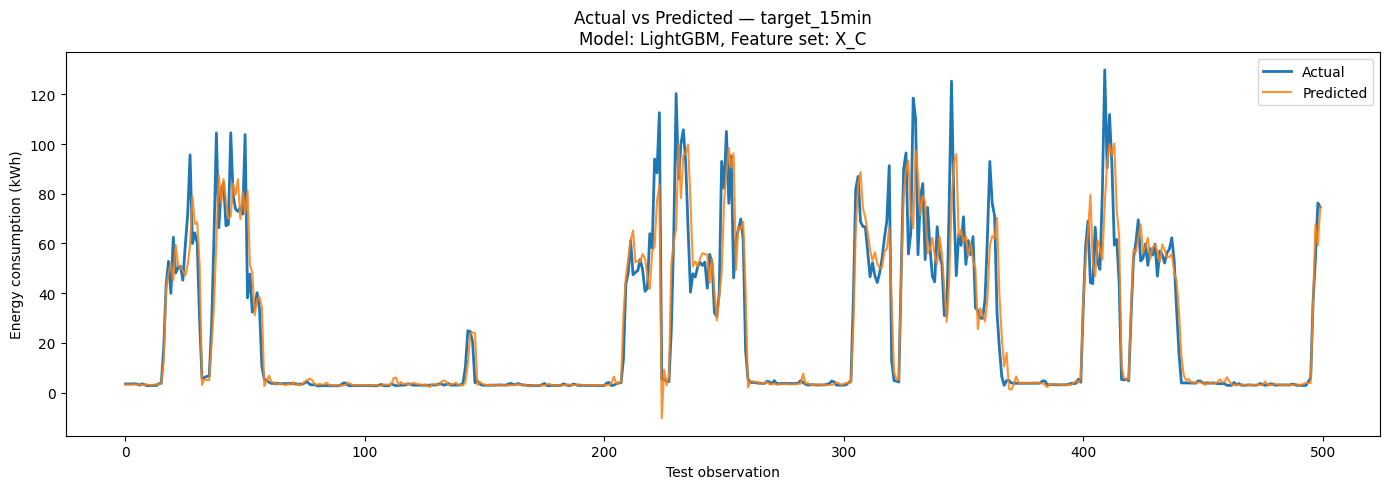

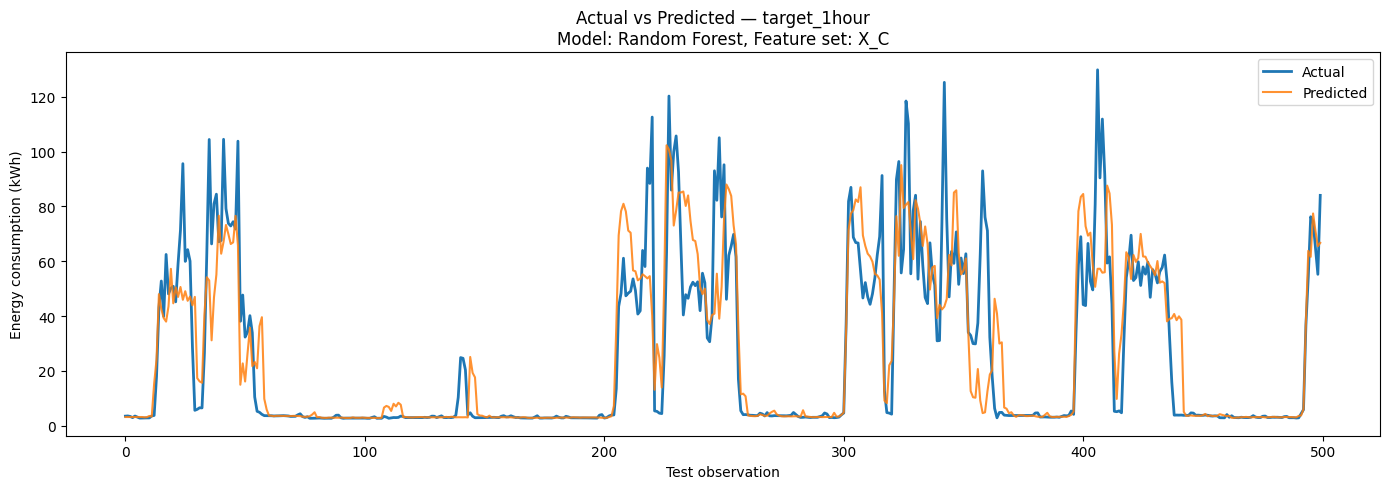

In [12]:
for target, info in selected_diagnostics.items():

    actual = info["actual"]
    predicted = info["predictions"]

    n = min(500, len(actual))

    plt.figure(figsize=(14, 5))
    plt.plot(actual[:n], label="Actual", linewidth=2)
    plt.plot(predicted[:n], label="Predicted", alpha=0.85)

    plt.title(
        f"Actual vs Predicted — {target}\n"
        f"Model: {info['key'][0]}, Feature set: {info['key'][1]}"
    )

    plt.xlabel("Test observation")
    plt.ylabel("Energy consumption (kWh)")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Residual distribution and bias

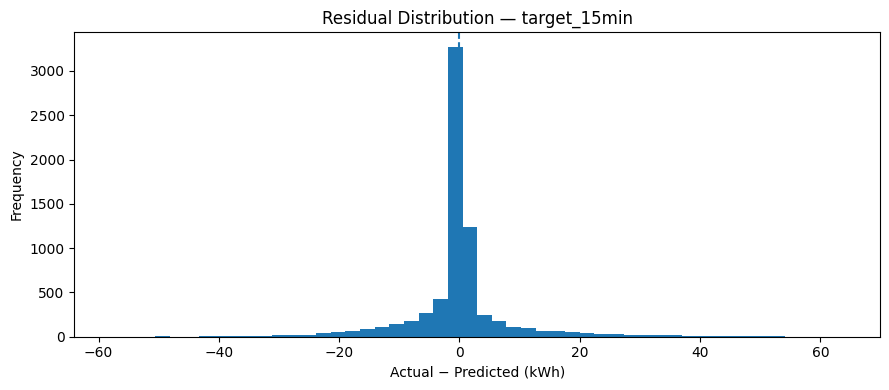

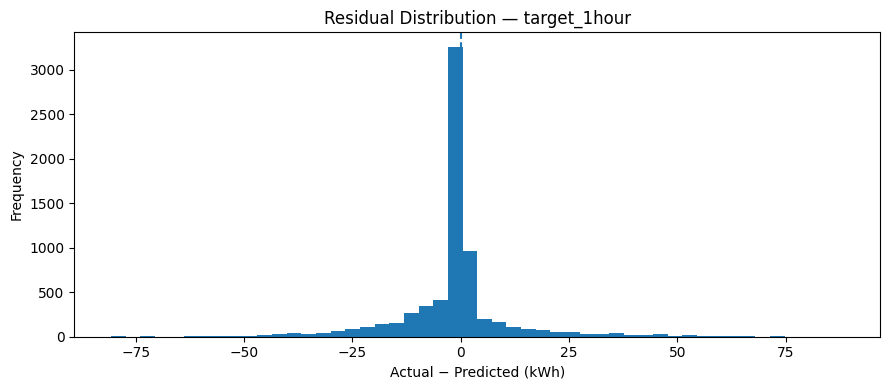

,Target,Model,Feature_Set,Mean_Residual,Median_Residual,Residual_Std,Maximum_Absolute_Error
0,target_15min,LightGBM,X_C,0.0111,0.0384,8.8083,63.8249
1,target_1hour,Random Forest,X_C,-1.0630,-0.1029,13.6627,88.3549


In [13]:
residual_summaries = []

for target, info in selected_diagnostics.items():

    actual = info["actual"]
    predicted = info["predictions"]

    residuals = actual - predicted

    residual_summaries.append({
        "Target": target,
        "Model": info["key"][0],
        "Feature_Set": info["key"][1],
        "Mean_Residual": np.mean(residuals),
        "Median_Residual": np.median(residuals),
        "Residual_Std": np.std(residuals),
        "Maximum_Absolute_Error": np.max(np.abs(residuals))
    })

    plt.figure(figsize=(9, 4))
    plt.hist(residuals, bins=50)
    plt.axvline(0, linestyle="--")
    plt.title(f"Residual Distribution — {target}")
    plt.xlabel("Actual − Predicted (kWh)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

residual_summary = pd.DataFrame(residual_summaries)

display(residual_summary.round(4))

## Error versus Predicted Value

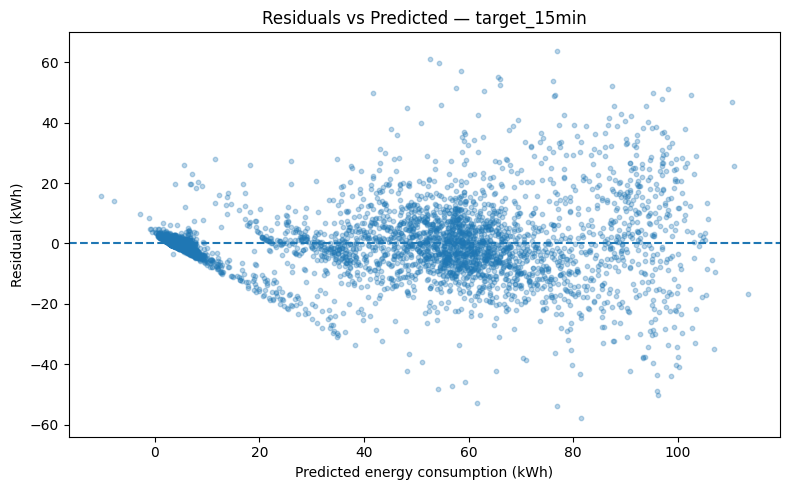

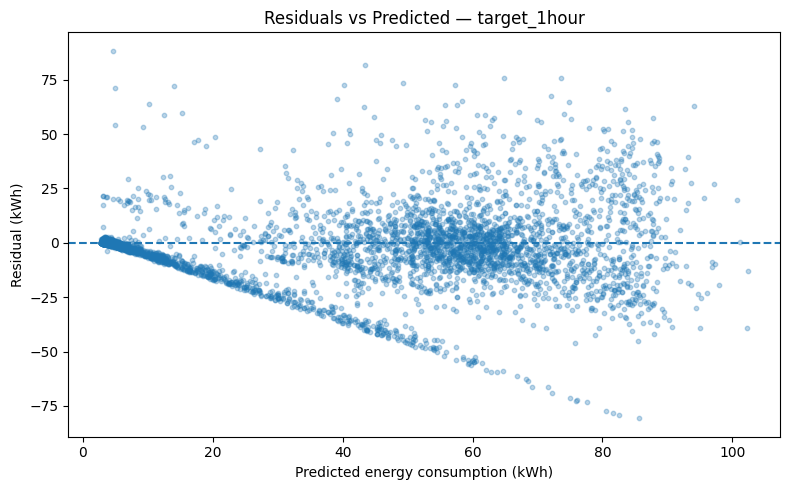

In [14]:
for target, info in selected_diagnostics.items():

    actual = info["actual"]
    predicted = info["predictions"]
    residuals = actual - predicted

    plt.figure(figsize=(8, 5))
    plt.scatter(predicted, residuals, alpha=0.3, s=10)
    plt.axhline(0, linestyle="--")

    plt.title(f"Residuals vs Predicted — {target}")
    plt.xlabel("Predicted energy consumption (kWh)")
    plt.ylabel("Residual (kWh)")
    plt.tight_layout()
    plt.show()

## Summarize the winning combinations

In [15]:
# Select the lowest-MAE model/feature-set combination per forecast horizon.
final_winners = (
    final_results
    .sort_values("MAE")
    .groupby("Target", as_index=False)
    .first()
)

display(final_winners.round(4))

print("Interpretation:")
for _, row in final_winners.iterrows():
    print(
        f"{row['Target']}: {row['Model']} with {row['Feature_Set']} "
        f"(MAE={row['MAE']:.4f}, RMSE={row['RMSE']:.4f}, "
        f"R²={row['R2']:.4f})"
    )

,Target,Model,Feature_Set,MAE,RMSE,R2,Runtime_seconds
0,target_15min,LightGBM,X_C,4.4155,8.8083,0.9213,0.6249
1,target_1hour,Random Forest,X_C,7.1156,13.7040,0.8095,7.8862


Interpretation:
target_15min: LightGBM with X_C (MAE=4.4155, RMSE=8.8083, R²=0.9213)
target_1hour: Random Forest with X_C (MAE=7.1156, RMSE=13.7040, R²=0.8095)


## Save outputs

In [16]:
RESULTS_DIR = DATA_DIR / "phase5_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(
    RESULTS_DIR / "cross_validation_fold_results.csv",
    index=False
)

cv_summary.to_csv(
    RESULTS_DIR / "cross_validation_summary.csv",
    index=False
)

final_results.to_csv(
    RESULTS_DIR / "final_test_results.csv",
    index=False
)

baseline_results.to_csv(
    RESULTS_DIR / "persistence_baseline_results.csv",
    index=False
)

baseline_comparison.to_csv(
    RESULTS_DIR / "baseline_comparison.csv",
    index=False
)

residual_summary.to_csv(
    RESULTS_DIR / "residual_summary.csv",
    index=False
)

final_winners.to_csv(
    RESULTS_DIR / "best_model_by_target.csv",
    index=False
)

print("Saved Phase 5 results to:", RESULTS_DIR.resolve())

Saved Phase 5 results to: D:\Research Paper Codes\Data\processed\phase5_results



## Findings, Verification, and Limitations

### 1. Main Findings

The study evaluated six regression algorithms across three feature sets for industrial energy consumption forecasting at 15-minute and one-hour horizons. The dataset comprised 34,940 observations collected between 2 January and 31 December 2018. A chronological split was used, with 27,948 observations allocated to training, four observations excluded through a purge gap, and 6,988 observations reserved for final testing.

Three-fold expanding-window time-series cross-validation was performed on the training data. For 15-minute-ahead forecasting, **LightGBM with feature set X_C** achieved the lowest mean cross-validation MAE of 5.0420, RMSE of 10.1364, and an average R² of 0.8968. For one-hour-ahead forecasting, **Random Forest with feature set X_A** achieved the lowest mean cross-validation MAE of 7.8567, RMSE of 14.9858, and an average R² of 0.7744.

On the held-out test set, LightGBM with X_C achieved an MAE of 4.4155, RMSE of 8.8083, and R² of 0.9213 for the 15-minute target. For the one-hour target, Random Forest with X_C achieved an MAE of 7.1156, RMSE of 13.7040, and R² of 0.8095. These results indicate that the tested models captured a substantial proportion of the variation in energy consumption, although performance varied across forecasting horizons and feature configurations.

### 2. Comparison with the Persistence Baseline

The persistence baseline was used to assess whether machine learning models improved upon a simple forecasting approach.

For the 15-minute forecasting horizon, the baseline MAE was 5.4830. LightGBM with X_C reduced the MAE to 4.4155, representing a **19.47% reduction in forecasting error**.

For the one-hour forecasting horizon, the baseline MAE was 12.4106. Random Forest with X_C achieved an MAE of 7.1156, corresponding to a **42.66% reduction in forecasting error**.

These comparisons suggest that the selected machine learning configurations provided better MAE performance than the persistence baseline on the held-out test period. However, not all evaluated configurations outperformed the baseline, indicating that model performance depended on the algorithm, feature set, and forecasting horizon.

### 3. Residual Analysis

Residual analysis was conducted to examine prediction errors, with residuals defined as the actual value minus the predicted value.

For the 15-minute LightGBM model with X_C, the mean residual was 0.0111, indicating negligible average signed error. The maximum absolute error was 63.8249.

For the one-hour Random Forest model with X_C, the mean residual was -1.0630, indicating a modest tendency toward overprediction on average. The maximum absolute error was 88.3549.

Although the mean residuals were relatively close to zero, the maximum absolute errors indicate that substantial errors occurred for individual observations. Further investigation of large residuals and high-consumption periods is therefore necessary to understand the models' limitations.

### 4. Verification and Methodological Limitations

The reported MAE improvements over the persistence baseline were verified using the recorded test metrics. The results indicate MAE reductions of approximately 19.47% for 15-minute forecasting and 42.66% for one-hour forecasting.

An important distinction exists between cross-validation model selection and test-set performance. Random Forest with X_A achieved the lowest mean cross-validation MAE for the one-hour target, whereas Random Forest with X_C achieved the lowest observed test MAE. For a defensible evaluation, the primary model should be selected using training-period cross-validation, and its performance should then be reported on the untouched test set. Selecting a model solely because it performs best across multiple test-set comparisons may produce optimistic estimates.

Feature availability is another important consideration. Feature set X_C includes current electrical sensor readings. These features are appropriate only if they are available at the forecast origin. Similarly, `usage_lag_0` should be excluded if current energy consumption is unavailable when the forecast is generated. This assumption must be verified before the model can be considered suitable for operational deployment.

The evaluation also relies on data from a single year. Consequently, the results may not fully represent performance under different operating conditions or across other years. In addition, the stored notebook outputs were inspected, but the complete experiment was not independently rerun from beginning to end. Reproducibility and feature-leakage checks remain necessary before the findings are treated as final.

### 5. Conclusion

The experimental results suggest that tree-based ensemble methods, particularly LightGBM and Random Forest, are promising approaches for industrial energy consumption forecasting. LightGBM with X_C achieved the strongest observed test performance for the 15-minute horizon, while Random Forest with X_C achieved the lowest observed test MAE for the one-hour horizon. Both configurations outperformed the persistence baseline in terms of MAE on the recorded test period.

Nevertheless, the findings should be interpreted in the context of feature availability, model-selection methodology, residual behaviour, and the limited temporal coverage of the dataset. The final conclusions should be established after rerunning the notebook, confirming that all predictors are available at forecast time, and reporting the test performance of models selected through cross-validation.



## Conclusions and Limitations

### Conclusions

This notebook compares six regression models across three feature sets for 15-minute and one-hour-ahead industrial energy-consumption forecasting. The recorded results indicate that LightGBM and Random Forest are promising candidates, with both achieving lower test-set MAE than the persistence baseline in their best-performing configurations.

The final model selection should be based on chronological cross-validation, followed by evaluation on the untouched holdout set. The reported improvements should be interpreted in conjunction with RMSE, R², residual analysis, and the practical availability of predictor variables.

### Limitations

- **Feature availability:** X_C includes current electrical sensor measurements, which must be available at forecast origin to support operational forecasting.
- **Hyperparameter optimization:** The evaluated hyperparameters represent initial configurations rather than an exhaustive search.
- **Temporal generalizability:** The dataset covers a single year, and the holdout period may not represent all operating conditions.
- **Model selection:** Choosing a model solely on the lowest test-set error can lead to optimistic performance estimates.
- **Reproducibility:** The notebook should be executed from the first cell to the last to verify the reported results.

